In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Normalize
scaler = StandardScaler()
X = scaler.fit_transform(X)

# One-hot encode labels
Y = np.eye(len(np.unique(y)))[y]   # convert to one-hot (150,3)

# Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)


In [ ]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_deriv(x):
    return sigmoid(x) * (1 - sigmoid(x))

In [ ]:
input_size = X_train.shape[1]   # 4 features
hidden_size = 5                 # 5 neurons in hidden layer
output_size = Y_train.shape[1]  # 3 output classes
learning_rate = 0.1
epochs = 200

np.random.seed(42)
W1 = np.random.rand(input_size, hidden_size)
b1 = np.random.rand(1, hidden_size)
W2 = np.random.rand(hidden_size, output_size)
b2 = np.random.rand(1, output_size)

In [ ]:
losses, accuracies = [], []

for epoch in range(epochs):
    z1 = np.dot(X_train, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    y_hat = sigmoid(z2)

    loss = np.mean(0.5 * (Y_train - y_hat)**2)
    losses.append(loss)

    predictions = np.argmax(y_hat, axis=1)
    labels = np.argmax(Y_train, axis=1)
    acc = np.mean(predictions == labels)
    accuracies.append(acc)

    delta_output = (Y_train - y_hat) * sigmoid_deriv(z2)
    delta_hidden = sigmoid_deriv(z1) * np.dot(delta_output, W2.T)

    W2 += learning_rate * np.dot(a1.T, delta_output)
    b2 += learning_rate * np.sum(delta_output, axis=0, keepdims=True)
    W1 += learning_rate * np.dot(X_train.T, delta_hidden)
    b1 += learning_rate * np.sum(delta_hidden, axis=0, keepdims=True)

    if (epoch+1) % 20 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss={loss:.4f}     Accuracy={acc:.4f}")


Epoch 20/200 | Loss=0.0452     Accuracy=0.8583
Epoch 40/200 | Loss=0.0228     Accuracy=0.9667
Epoch 60/200 | Loss=0.0123     Accuracy=0.9583
Epoch 80/200 | Loss=0.0091     Accuracy=0.9583
Epoch 100/200 | Loss=0.0078     Accuracy=0.9750
Epoch 120/200 | Loss=0.0070     Accuracy=0.9750
Epoch 140/200 | Loss=0.0066     Accuracy=0.9833
Epoch 160/200 | Loss=0.0063     Accuracy=0.9833
Epoch 180/200 | Loss=0.0061     Accuracy=0.9833
Epoch 200/200 | Loss=0.0059     Accuracy=0.9833


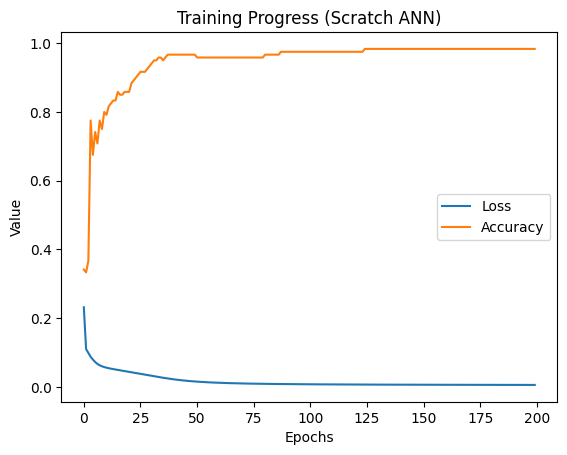

In [ ]:
plt.plot(losses, label="Loss")
plt.plot(accuracies, label="Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Value")
plt.legend()
plt.title("Training Progress (Scratch ANN)")
plt.show()

In [ ]:
z1_test = np.dot(X_test, W1) + b1
a1_test = sigmoid(z1_test)
z2_test = np.dot(a1_test, W2) + b2
y_pred = sigmoid(z2_test)

predictions_test = np.argmax(y_pred, axis=1)
labels_test = np.argmax(Y_test, axis=1)
test_acc = np.mean(predictions_test == labels_test)

print(" Test Accuracy (Scratch ANN):", test_acc)

 Test Accuracy (Scratch ANN): 1.0
